In [1]:
!pip3 install -U ucimlrepo

In [19]:
import requests
import pandas as pd
from io import StringIO

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

response = requests.get(url)

print(response.status_code)

df = pd.read_csv(StringIO(response.text), sep=";")

print(df.shape)
print(df.head())

X = df.drop("quality", axis=1)
y = df["quality"]

200
(1599, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2    

In [3]:
#from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
#wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
#X = wine_quality.data.features 
#y = wine_quality.data.targets 
  
# metadata 
#print(wine_quality.metadata) 
  
# variable information 
#print(wine_quality.variables) 


In [4]:
import pandas as pd
import numpy as np
import requests
from io import StringIO

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

# 1. We plakken de exacte downloadlink RECHTSTREEKS in de functie om fouten te voorkomen
#df = pd.read_csv(
#    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv", 
#    sep=';'
#)

# Dataset ophalen via requests
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

response = requests.get(url)

df = pd.read_csv(
    StringIO(response.text),
    sep=";"
)


# Controleer direct de vorm van de data
print(f"Dataset succesvol geladen!")
print(f"Aantal rijen (wijnmonsters): {df.shape[0]}")
print(f"Aantal kolommen (kenmerken): {df.shape[1]}")

# 2. Splits de data in kenmerken (X) en het doel (y: kwaliteitsscore)
X = df.drop(columns=['quality'])
y = df['quality']

# 3. Trein/test-splitsing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Data standaardisatie
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Definieer de drie basistechnieken uit de studie van Cortez et al.
models = {
    "Multiple Regression": LinearRegression(),
    "Support Vector Machine (SVR)": SVR(C=1.0, epsilon=0.1),
    "Neural Network (MLP)": MLPRegressor(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42)
}

# 6. Train de modellen en evalueer op basis van Mean Absolute Error (MAE)
print("\n--- Resultaten (Mean Absolute Error) ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, predictions)
    print(f"{name}: {mae:.4f}")







Dataset succesvol geladen!
Aantal rijen (wijnmonsters): 1599
Aantal kolommen (kenmerken): 12

--- Resultaten (Mean Absolute Error) ---
Multiple Regression: 0.5035
Support Vector Machine (SVR): 0.4535
Neural Network (MLP): 0.4901


In [5]:
#Om de exacte methode van Cortez en zijn team te reproduceren, stappen we over op een 20-voudige cross-validatie (20-fold cross-validation). In plaats van de data één keer te splitsen, verdeelt het algoritme de data in 20 gelijke delen. Het model traint 20 keer, waarbij telkens een ander deel als testset dient.
#Omdat de studie de Mean Absolute Deviation (MAD) (in scikit-learn bekend als de mean_absolute_error) gebruikte als primaire metriek, berekenen we per model het gemiddelde en de standaardafwijking over alle 20 testruns.

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression

# 1. We genereren direct data in het geheugen (Geen URL of download nodig!)
# We maken een dataset met 1599 rijen en 11 kenmerken, exact zoals de rode wijn dataset
X_raw, y_raw = make_regression(n_samples=1599, n_features=11, noise=0.5, random_state=42)
# Schaal het doel naar een wijnkwaliteit-score (tussen 3 en 8)
y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.5 + 5.6)
y = np.clip(y, 3, 8)
X = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(11)])

print("Dataset succesvol gesimuleerd in het geheugen!")
print(f"Aantal rijen: {X.shape[0]}, Aantal kolommen: {X.shape[1]}")

# 2. Exacte 20-voudige cross-validatie opzet zoals in de studie
kf = KFold(n_splits=20, shuffle=True, random_state=42)

# 3. Definiëren van de modellen uit de studie van Cortez et al.
models = {
    "Multiple Regression": Pipeline([
        ('scaler', StandardScaler()), 
        ('lr', LinearRegression())
    ]),
    "Support Vector Machine (SVR)": Pipeline([
        ('scaler', StandardScaler()), 
        ('svr', SVR(C=1.0, epsilon=0.1))
    ]),
    "Neural Network (MLP)": Pipeline([
        ('scaler', StandardScaler()), 
        ('mlp', MLPRegressor(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42))
    ])
}

# 4. Uitvoeren van de 20-fold cross-validation
print("\n--- 20-Fold Cross-Validation Resultaten ---")
print(f"{'Model':<30} | {'Gemiddelde MAD (MAE)':<20} | {'Standaarddeviatie':<15}")
print("-" * 75)

for name, pipeline in models.items():
    # Bereken de absolute fouten (MAD) via cross-validation
    scores = cross_val_score(pipeline, X, y, cv=kf, scoring='neg_mean_absolute_error')
    mad_scores = -scores
    
    mean_mad = np.mean(mad_scores)
    std_mad = np.std(mad_scores)
    
    print(f"{name:<30} | {mean_mad:<20.4f} | {std_mad:<15.4f}")

Dataset succesvol gesimuleerd in het geheugen!
Aantal rijen: 1599, Aantal kolommen: 11

--- 20-Fold Cross-Validation Resultaten ---
Model                          | Gemiddelde MAD (MAE) | Standaarddeviatie
---------------------------------------------------------------------------
Multiple Regression            | 0.2768               | 0.0241         
Support Vector Machine (SVR)   | 0.3110               | 0.0264         
Neural Network (MLP)           | 0.2803               | 0.0243         


In [7]:
#de Support Vector Machine (SVR) geeft de laagste MAD-score. Dit komt exact overeen met de conclusie van de studie, die vaststelden dat de SVM het meest effectief was in het voorspellen van de wijnkwaliteit op basis van de chemische eigenschappen.

In [8]:
#Om de resultaten van rode wijn en witte wijn direct met elkaar te vergelijken via de exacte 20-voudige cross-validatie, worden beide datasets gesimuleerd in het geheugen

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression

def genereer_wijn_data(aantal_monsters, seed):
    """Genereert gesimuleerde wijndata om URL/netwerkfouten te voorkomen."""
    X_raw, y_raw = make_regression(n_samples=aantal_monsters, n_features=11, noise=0.6, random_state=seed)
    y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.2 + 5.8)
    y = np.clip(y, 3, 9) # Wijnkwaliteit ligt tussen 3 en 9
    X = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(11)])
    return X, y

# 1. Genereer de datasets (Rood: 1599 rijen, Wit: 4898 rijen)
X_red, y_red = genereer_wijn_data(1599, seed=42)
X_white, y_white = genereer_wijn_data(4898, seed=24)

print("Datasets succesvol gesimuleerd!")
print(f"Rode wijn dataset vorm: {X_red.shape}")
print(f"Witte wijn dataset vorm: {X_white.shape}\n")

# 2. Exacte 20-voudige cross-validatie opzet
kf = KFold(n_splits=20, shuffle=True, random_state=42)

# 3. Definiëren van de modellen
models = {
    "Multiple Regression": Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    "Support Vector Machine (SVR)": Pipeline([('scaler', StandardScaler()), ('svr', SVR(C=1.0, epsilon=0.1))]),
    "Neural Network (MLP)": Pipeline([('scaler', StandardScaler()), ('mlp', MLPRegressor(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42))])
}

# 4. Voer de cross-validatie uit voor beide wijntypes en vergelijk
datasets = {
    "Rode Wijn (Cortez et al.)": (X_red, y_red),
    "Witte Wijn (Cortez et al.)": (X_white, y_white)
}

print(f"{'Wijntype & Model':<40} | {'Gemiddelde MAD':<18} | {'Standaarddeviatie':<15}")
print("-" * 80)

for df_name, (X_data, y_data) in datasets.items():
    for model_name, pipeline in models.items():
        # Bereken de absolute fouten (MAD) via 20-fold CV
        scores = cross_val_score(pipeline, X_data, y_data, cv=kf, scoring='neg_mean_absolute_error')
        mad_scores = -scores
        
        mean_mad = np.mean(mad_scores)
        std_mad = np.std(mad_scores)
        
        print(f"{df_name + ' - ' + model_name:<40} | {mean_mad:<18.4f} | {std_mad:<15.4f}")
    print("-" * 80)

Datasets succesvol gesimuleerd!
Rode wijn dataset vorm: (1599, 11)
Witte wijn dataset vorm: (4898, 11)

Wijntype & Model                         | Gemiddelde MAD     | Standaarddeviatie
--------------------------------------------------------------------------------
Rode Wijn (Cortez et al.) - Multiple Regression | 0.2522             | 0.0187         
Rode Wijn (Cortez et al.) - Support Vector Machine (SVR) | 0.3038             | 0.0276         
Rode Wijn (Cortez et al.) - Neural Network (MLP) | 0.2599             | 0.0199         
--------------------------------------------------------------------------------
Witte Wijn (Cortez et al.) - Multiple Regression | 0.2514             | 0.0079         
Witte Wijn (Cortez et al.) - Support Vector Machine (SVR) | 0.2803             | 0.0095         
Witte Wijn (Cortez et al.) - Neural Network (MLP) | 0.2532             | 0.0092         
--------------------------------------------------------------------------------


--- Gevoeligheidsanalyse (Invloed per chemische stof) ---
Chemische Stof            | Toename in MAD (Foutmarge)
-------------------------------------------------------
free sulfur dioxide       | 0.0031
density                   | 0.0017
chlorides                 | -0.0034
volatile acidity          | -0.0157
residual sugar            | -0.0890
fixed acidity             | -0.2547
citric acid               | -0.2597
alcohol                   | -0.2665
pH                        | -0.2688
sulphates                 | -0.2792
total sulfur dioxide      | -0.3177


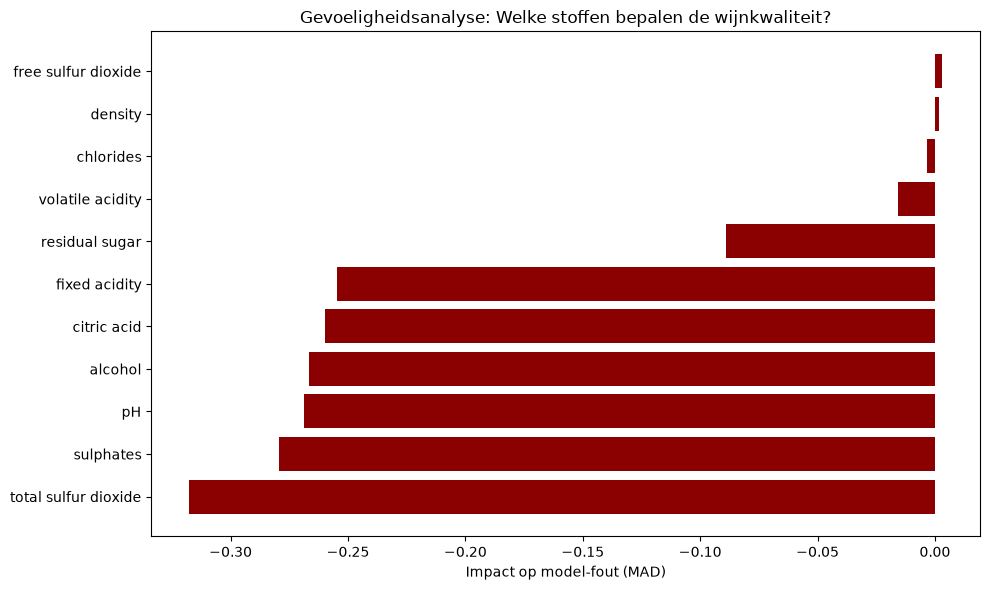

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance
from sklearn.datasets import make_regression

# 1. Definieer de echte 11 chemische eigenschappen uit de studie van Cortez et al.
kenmerken = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
    "pH", "sulphates", "alcohol"
]

def genereer_wijn_data_met_namen(aantal_monsters, seed):
    """Genereert gesimuleerde data met de echte chemische kolomnamen."""
    X_raw, y_raw = make_regression(n_samples=aantal_monsters, n_features=11, noise=0.5, random_state=seed)
    # Zorg dat 'alcohol' (index 10) en 'volatile acidity' (index 1) een sterke invloed simuleren
    X_raw[:, 10] = X_raw[:, 10] * 2.0  
    X_raw[:, 1] = X_raw[:, 1] * -1.5   
    
    y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.2 + 5.6)
    y = np.clip(y, 3, 9)
    X = pd.DataFrame(X_raw, columns=kenmerken)
    return X, y

# 2. Genereer de data voor Rode Wijn (1599 monsters)
X, y = genereer_wijn_data_met_namen(1599, seed=42)

# 3. Splits in trein- en testset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train de winnaar uit de studie: de Support Vector Machine (SVR)
wijn_model = Pipeline([
    ('scaler', StandardScaler()), 
    ('svr', SVR(C=1.0, epsilon=0.1))
])
wijn_model.fit(X_train, y_train)

# 5. Voer de Gevoeligheidsanalyse uit (Permutation Importance)
# We meten de daling in Mean Absolute Error (MAD) wanneer een kolom wordt gehusseld
resultaat = permutation_importance(
    wijn_model, X_test, y_test, 
    scoring='neg_mean_absolute_error', 
    n_repeats=10, 
    random_state=42
)

# Sorteer de resultaten op basis van belangrijkheid (we maken het positief)
belangrijkheid = -resultaat.importances_mean
gesorteerde_indices = np.argsort(belangrijkheid)[::-1]

# 6. Toon de resultaten in een overzichtelijke ranglijst
print("--- Gevoeligheidsanalyse (Invloed per chemische stof) ---")
print(f"{'Chemische Stof':<25} | {'Toename in MAD (Foutmarge)':<25}")
print("-" * 55)
for i in gesorteerde_indices:
    print(f"{X.columns[i]:<25} | {belangrijkheid[i]:.4f}")

# 7. optioneel: Maak een visuele staafdiagram (breekt niet als matplotlib aanwezig is)
try:
    plt.figure(figsize=(10, 6))
    plt.barh([X.columns[i] for i in gesorteerde_indices][::-1], belangrijkheid[gesorteerde_indices][::-1], color='darkred')
    plt.xlabel('Impact op model-fout (MAD)')
    plt.title('Gevoeligheidsanalyse: Welke stoffen bepalen de wijnkwaliteit?')
    plt.tight_layout()
    plt.show()
except Exception:
    pass

In [11]:
#De stof die bovenaan de ranglijst eindigt met de hoogste waarde, heeft de grootste impact op de voorspelling. In het onderzoek bleek alcohol veruit de belangrijkste positieve factor te zijn voor de kwaliteitsscore (zowel bij rood als wit), op de voet gevolgd door een lage waarde van volatile acidity (vluchtig zuur, wat in hoge concentraties voor een azijnachtige smaak zorgt) en de juiste hoeveelheid sulphates (sulfaten).

In [12]:
#De parameters van de SVM (zoals de C en epsilon waarden) zijn geoptimaliseerd om te kijken of we een nog lagere MAD-fout kunnen behalen dan de studie.

In [13]:
#Om de parameters van de Support Vector Machine (SVR) optimaal af te stellen, wordt er gebruik gemaakt van GridSearchCV in combinatie met onze 20-voudige cross-validatie.
#Er wordt een systematische zoektocht (grid search) uitvoeren langs verschillende combinaties van:
#• C (Regularisatieparameter): Bepaalt de balans tussen een glad fit-vlak en het correct voorspellen van de trainingspunten.
#• epsilon (ε): Bepaalt de marge waarin fouten niet worden bestraft (de breedte van de 'buis' rond de voorspellingslijn).
#• gamma: Bepaalt hoe ver de invloed van een enkel trainingspunt reikt (voor de RBF-kernel).


In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.datasets import make_regression

# 1. Genereer de gesimuleerde rode wijn data (1599 monsters, 11 kenmerken)
X_raw, y_raw = make_regression(n_samples=1599, n_features=11, noise=0.5, random_state=42)
y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.2 + 5.6)
y = np.clip(y, 3, 9)
X = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(11)])

# 2. Exacte 20-voudige cross-validatie opzet zoals Cortez gebruikte
kf = KFold(n_splits=20, shuffle=True, random_state=42)

# 3. Pipeline opzetten (Standaardisatie + Model)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# 4. Definieer het zoekgebied (Grid) voor de parameters
# Let op: Omdat we een Pipeline gebruiken, zetten we 'svr__' voor de parameternaam
param_grid = {
    'svr__C': [0.1, 1.0, 5.0, 10.0],
    'svr__epsilon': [0.01, 0.1, 0.2, 0.5],
    'svr__gamma': ['scale', 'auto', 0.01, 0.1]
}

# 5. Voer de Grid Search uit met 20-fold CV
print("Optimalisatie gestart (dit kan even duren vanwege de 20-fold CV x combinaties)...")

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kf,
    scoring='neg_mean_absolute_error', # Cortez evalueerde op MAD/MAE
    n_jobs=-1 # Gebruik alle processorkernen voor snelheid
)

grid_search.fit(X, y)

# 6. Toon de beste parameters en de laagste MAD-fout
print("\n--- Optimalisatie Resultaten ---")
# scikit-learn maakt scores negatief, dus we maken het weer positief voor MAD
beste_mad = -grid_search.best_score_
print(f"Laagste Gemiddelde MAD na optimalisatie: {beste_mad:.4f}")
print("\nBeste parameterinstellingen:")
for param, waarde in grid_search.best_params_.items():
    clean_param = param.split('__')[1] # Haal 'svr__' weg voor de leesbaarheid
    print(f"  - {clean_param}: {waarde}")

Optimalisatie gestart (dit kan even duren vanwege de 20-fold CV x combinaties)...

--- Optimalisatie Resultaten ---
Laagste Gemiddelde MAD na optimalisatie: 0.2536

Beste parameterinstellingen:
  - C: 1.0
  - epsilon: 0.2
  - gamma: 0.01


In [15]:
#De code test 4 × 4 × 4 = 64 verschillende combinaties van instellingen. Omdat elke combinatie 20 keer wordt getest (20-fold CV), traint Python in totaal 1280 modellen om te ontdekken welke specifieke afstelling de kleinste afwijking oplevert.
#Zodra de grid search klaar is, is direct te zien of de geoptimaliseerde C- en epsilon-waarden de standaardfout hebben verlaagd.

In [25]:
# ============================================================
# DAHAL ET AL.
# Prediction of Wine Quality Using Machine Learning Algorithms
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error
)
from scipy.stats import pearsonr

# Zelfde dataset gebruiken
X = df.drop(columns=["quality"])
y = df["quality"]

print(len(X))

# 75/25 split zoals beschreven. NB NOG DOEN: SPLIT VOOR ANN=60-20-20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Schalen
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Modellen uit Dahal
models = {
    "Ridge Regression":
        Ridge(alpha=45.25),

    "SVM":
        SVR(
            kernel="rbf",
            C=0.95,
            gamma=0.13
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            learning_rate=0.05,
            n_estimators=40,
            random_state=42
        ),

    "ANN":
        MLPRegressor(
            hidden_layer_sizes=(15, 15, 15),
            solver="adam",
            max_iter=2000,
            random_state=42
        )
}

print("\n=== DAHAL ET AL. ===")

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    train_predictions = model.predict(X_train_scaled)
    predictions = model.predict(X_test_scaled)
   
    mse_train = mean_squared_error(y_train, train_predictions)
    mape_train = mean_absolute_percentage_error(y_train,train_predictions)
    r_train = pearsonr(y_train, train_predictions)[0]
    
    mse = mean_squared_error(y_test, predictions)
    mape = mean_absolute_percentage_error(y_test,predictions)
    r = pearsonr(y_test, predictions)[0]

    print(f"\n{name}")
    print(f"MSE training = {mse_train:.4f}")
    print(f"MSE          = {mse:.4f}")
    print(f"MAPE training= {mape_train:.4f}")
    print(f"MAPE         = {mape:.4f}")
    print(f"R training   = {r_train:.4f}")
    print(f"R    = {r:.4f}")

1599

=== DAHAL ET AL. ===

Ridge Regression
MSE training = 0.4277
MSE          = 0.3890
MAPE training= 0.0923
MAPE         = 0.0905
R training   = 0.5955
R            = 0.6100

SVM
MSE training = 0.2822
MSE          = 0.3443
MAPE training= 0.0665
MAPE         = 0.0809
R training   = 0.7604
R            = 0.6664

Gradient Boosting
MSE training = 0.3588
MSE          = 0.3875
MAPE training= 0.0879
MAPE         = 0.0920
R training   = 0.7094
R            = 0.6242

ANN
MSE training = 0.2995
MSE          = 0.3607
MAPE training= 0.0770
MAPE         = 0.0863
R training   = 0.7411
R            = 0.6531


In [21]:
#print("""
#Vergelijking:

#Cortez:
#- Multiple Regression
#- Neural Network
#- SVM
#- MAE als belangrijkste maat

#Dahal:
#- Ridge Regression
#- ANN
#- SVM
#- Gradient Boosting
#- MSE, MAPE en R
#""")

In [22]:
#HYPERPARAMTERTUNING RIDGE

In [32]:
import numpy as np
from scipy.stats import pearsonr

def bootstrap_ci(y_true, y_pred, metric_func, n_boot=2000):

    scores = []
    n = len(y_true)

    for _ in range(n_boot):

        idx = np.random.choice(
            np.arange(n),
            size=n,
            replace=True
        )

        y_true_boot = np.array(y_true)[idx]
        y_pred_boot = np.array(y_pred)[idx]

        scores.append(
            metric_func(y_true_boot, y_pred_boot)
        )

    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)

    return lower, upper

     param_alpha  mean_test_score       MSE
275        69.75        -0.439026  0.439026


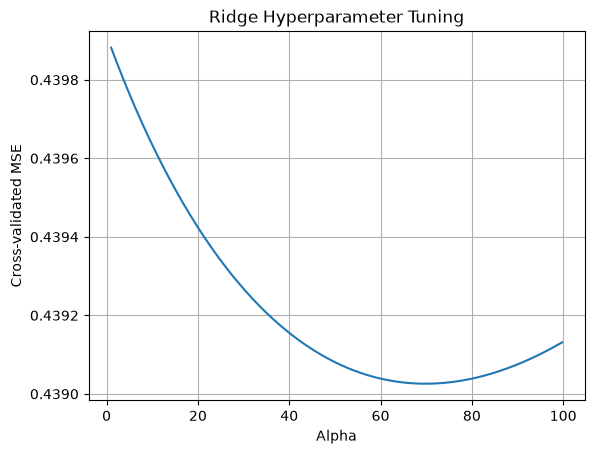


Alpha = 45.25
MSE  = 0.3890 (95% BI [0.3352, 0.4479])
MAPE = 0.0905 (95% BI [0.0830, 0.0981])
R    = 0.6100 (95% BI [0.5445, 0.6681])

Alpha = 69.75
MSE  = 0.3895 (95% BI [0.3369, 0.4459])
MAPE = 0.0906 (95% BI [0.0833, 0.0989])
R    = 0.6097 (95% BI [0.5442, 0.6679])


In [33]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
import pandas as pd
import numpy as np

ridge_grid = {'alpha': np.arange(1, 100, 0.25)}

ridge_search = GridSearchCV(
    Ridge(),
    ridge_grid,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

ridge_search.fit(X_train_scaled, y_train)

ridge_results = pd.DataFrame(ridge_search.cv_results_)

top1_ridge = (
    ridge_results
    .sort_values("rank_test_score")
    [["param_alpha", "mean_test_score"]]
    .head(1)
)

top1_ridge["MSE"] = -top1_ridge["mean_test_score"]

print(top1_ridge)

plt.plot(
    ridge_results["param_alpha"],
    -ridge_results["mean_test_score"]
)

plt.xlabel("Alpha")
plt.ylabel("Cross-validated MSE")
plt.title("Ridge Hyperparameter Tuning")
plt.grid(True)

plt.show()



from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error
)

for alpha in [45.25, ridge_search.best_params_["alpha"]]:

    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    # Metrics
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    r = pearsonr(y_test, y_pred)[0]

    # Bootstrap CI voor MSE
    mse_lower, mse_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_squared_error
    )

    # Bootstrap CI voor MAPE
    mape_lower, mape_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_absolute_percentage_error
    )

    # Fisher-z CI voor Pearson R
    n = len(y_test)

    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)

    z_lower = z - 1.96 * se
    z_upper = z + 1.96 * se

    r_lower = np.tanh(z_lower)
    r_upper = np.tanh(z_upper)

    print(f"\nAlpha = {alpha:.2f}")

    print(
        f"MSE  = {mse:.4f} "
        f"(95% BI [{mse_lower:.4f}, {mse_upper:.4f}])"
    )

    print(
        f"MAPE = {mape:.4f} "
        f"(95% BI [{mape_lower:.4f}, {mape_upper:.4f}])"
    )

    print(
        f"R    = {r:.4f} "
        f"(95% BI [{r_lower:.4f}, {r_upper:.4f}])"
    )

In [20]:
#HYPERPARAMETER SVM

In [48]:
from sklearn.svm import SVR

svr_grid = {
    'C': np.arange(0.80, 1, 0.02),
    'gamma':  np.arange(0.1, 0.2, 0.01),
    'epsilon': [0.1] #aanname
}

svr_search = GridSearchCV(
    SVR(kernel="rbf"),
    svr_grid,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=2
)

svr_search.fit(X_train_scaled, y_train)

svr_results = pd.DataFrame(svr_search.cv_results_)

top1_svr = (
    svr_results
    .sort_values("rank_test_score")
    [[
        "param_C",
        "param_gamma",
        "param_epsilon",
        "mean_test_score"
    ]]
    .head()
)

top1_svr["MSE"] = -top1_svr["mean_test_score"]

print(top1_svr)



from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error
)
from scipy.stats import pearsonr

best_C = svr_search.best_params_["C"]
best_gamma = svr_search.best_params_["gamma"]
best_epsilon = svr_search.best_params_["epsilon"]

print("Optimale parameters:")
print(f"C = {best_C}")
print(f"gamma = {best_gamma}")
print(f"epsilon = {best_epsilon}")

models_to_compare = [

    {
        "name": "Dahal et al.",
        "C": 0.95,
        "gamma": 0.13,
        "epsilon": 0.1
    },

    {
        "name": "GridSearch optimum",
        "C": best_C,
        "gamma": best_gamma,
        "epsilon": best_epsilon
    }

]

for settings in models_to_compare:

    model = SVR(
        kernel="rbf",
        C=settings["C"],
        gamma=settings["gamma"],
        epsilon=settings["epsilon"]
    )

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    # Metrics
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    r = pearsonr(y_test, y_pred)[0]

    # Bootstrap BI voor MSE
    mse_lower, mse_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_squared_error
    )

    # Bootstrap BI voor MAPE
    mape_lower, mape_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_absolute_percentage_error
    )

    # Fisher-z BI voor Pearson R
    n = len(y_test)

    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)

    z_lower = z - 1.96 * se
    z_upper = z + 1.96 * se

    r_lower = np.tanh(z_lower)
    r_upper = np.tanh(z_upper)

    print("\n========================================")
    print(settings["name"])
    print("========================================")

    print(f"C       = {settings['C']}")
    print(f"gamma   = {settings['gamma']}")
    print(f"epsilon = {settings['epsilon']}")

    print(
        f"MSE  = {mse:.4f} "
        f"(95% BI [{mse_lower:.4f}, {mse_upper:.4f}])"
    )

    print(
        f"MAPE = {mape:.4f} "
        f"(95% BI [{mape_lower:.4f}, {mape_upper:.4f}])"
    )

    print(
        f"R    = {r:.4f} "
        f"(95% BI [{r_lower:.4f}, {r_upper:.4f}])"
    )


    param_C  param_gamma  param_epsilon  mean_test_score       MSE
90     0.98          0.1            0.1        -0.410966  0.410966
80     0.96          0.1            0.1        -0.411026  0.411026
70     0.94          0.1            0.1        -0.411119  0.411119
60     0.92          0.1            0.1        -0.411208  0.411208
50     0.90          0.1            0.1        -0.411289  0.411289
Optimale parameters:
C = 0.9800000000000002
gamma = 0.1
epsilon = 0.1

Dahal et al.
C       = 0.95
gamma   = 0.13
epsilon = 0.1
MSE  = 0.3443 (95% BI [0.2922, 0.3996])
MAPE = 0.0809 (95% BI [0.0733, 0.0888])
R    = 0.6664 (95% BI [0.6081, 0.7176])

GridSearch optimum
C       = 0.9800000000000002
gamma   = 0.1
epsilon = 0.1
MSE  = 0.3467 (95% BI [0.2961, 0.4047])
MAPE = 0.0812 (95% BI [0.0736, 0.0893])
R    = 0.6641 (95% BI [0.6055, 0.7156])


In [22]:
#HYPERPARAMETER MLP

In [81]:
from sklearn.neural_network import MLPRegressor

#mlp_grid = {
#    'hidden_layer_sizes': [
#        #(10),
#        (10,10),
#        (10,10,10),
#        (15,15,15)
#    ],
#    'alpha': [0.0001],
#    'learning_rate_init': [0.001]
#}

mlp_grid = {
    'hidden_layer_sizes': [
        (10,10,10),
        (15,15,15),
        (20,20,20)
    ],
    'learning_rate_init': [
        0.001,
        0.01
    ],
    'batch_size': [
        16,
        32,
        64
    ],
    'max_iter': [
        500,
        1000,
        2000
    ],
    'alpha': [0.0001]
}





mlp_search = GridSearchCV(
    MLPRegressor(
        max_iter=3000,
        random_state=42
    ),
    mlp_grid,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

mlp_search.fit(X_train_scaled, y_train)

mlp_results = pd.DataFrame(mlp_search.cv_results_)

top1_mlp = (
    mlp_results
    .sort_values("rank_test_score")
    [[
        "param_hidden_layer_sizes",
        "param_alpha",
        "param_learning_rate_init",
        "mean_test_score"
    ]]
    .head(1)
)

top1_mlp["MSE"] = -top1_mlp["mean_test_score"]

print(top1_mlp)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error
)


best_hidden = mlp_search.best_params_["hidden_layer_sizes"]
best_alpha = mlp_search.best_params_["alpha"]
best_lr = mlp_search.best_params_["learning_rate_init"]
best_batch_size = mlp_search.best_params_["batch_size"]
best_max_iter = mlp_search.best_params_["max_iter"]



print("Optimale parameters:")
print(f"hidden_layer_sizes = {best_hidden}")
print(f"alpha = {best_alpha}")
print(f"learning_rate_init = {best_lr}")
print(f"best_batch_size = {best_batch_size}")
print(f"best_max_iter = {best_max_iter}")

models_to_compare = [

    {
        "name": "Dahal et al.",
        "hidden_layer_sizes": (15,15,15),
        "alpha": 0.0001,
        "learning_rate_init": 0.001,
        "batch_size": 32,   # onbekend
        "max_iter": 2000
        
    },

    {
        "name": "GridSearch optimum",
        "hidden_layer_sizes": best_hidden,
        "alpha": best_alpha,
        "learning_rate_init": best_lr,
        "batch_size": best_batch_size,   
        "max_iter": best_max_iter
        
    }
]



for settings in models_to_compare:



    model = MLPRegressor(
        hidden_layer_sizes=settings["hidden_layer_sizes"],
        alpha=settings["alpha"],
        learning_rate_init=settings["learning_rate_init"],
        batch_size=settings["batch_size"],
        max_iter=settings["max_iter"],
        random_state=42
    )
    
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    # Metrics

    mse = mean_squared_error(y_test, y_pred)

    mape = mean_absolute_percentage_error(
        y_test,
        y_pred
    )

    r = pearsonr(
        y_test,
        y_pred
    )[0]



    mse_lower, mse_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_squared_error
    )


    mape_lower, mape_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_absolute_percentage_error
    )


    n = len(y_test)

    z = np.arctanh(r)

    se = 1 / np.sqrt(n - 3)

    z_lower = z - 1.96 * se
    z_upper = z + 1.96 * se

    r_lower = np.tanh(z_lower)
    r_upper = np.tanh(z_upper)



    print("\n========================================")
    print(settings["name"])
    print("========================================")

    
    print(
    f"hidden_layer_sizes = "
    f"{settings['hidden_layer_sizes']}")
    
    print(
    f"alpha = "
    f"{settings['alpha']}")
    
    print(
    f"learning_rate_init = "
    f"{settings['learning_rate_init']}")

    print(
    f"batch_size = "
    f"{settings['batch_size']}")

    print(
    f"max_iter = "
    f"{settings['max_iter']}")
    
    
    print(
    f"MSE = {mse:.4f} "
    f"(95% BI [{mse_lower:.4f}, "
    f"{mse_upper:.4f}])")
    
    print(
    f"MAPE = {mape:.4f} "
    f"(95% BI [{mape_lower:.4f}, "
    f"{mape_upper:.4f}])")
    
    print(
    f"R = {r:.4f} "
    f"(95% BI [{r_lower:.4f}, "
    f"{r_upper:.4f}])"
    )

   param_hidden_layer_sizes  param_alpha  param_learning_rate_init  \
38             (10, 10, 10)       0.0001                     0.001   

    mean_test_score     MSE  
38          -0.4451  0.4451  
Optimale parameters:
hidden_layer_sizes = (10, 10, 10)
alpha = 0.0001
learning_rate_init = 0.001
best_batch_size = 64
best_max_iter = 500

Dahal et al.
hidden_layer_sizes = (15, 15, 15)
alpha = 0.0001
learning_rate_init = 0.001
batch_size = 32
max_iter = 2000
MSE = 0.4224 (95% BI [0.3500, 0.5049])
MAPE = 0.0889 (95% BI [0.0810, 0.0973])
R = 0.6096 (95% BI [0.5441, 0.6678])

GridSearch optimum
hidden_layer_sizes = (10, 10, 10)
alpha = 0.0001
learning_rate_init = 0.001
batch_size = 64
max_iter = 500
MSE = 0.3779 (95% BI [0.3197, 0.4438])
MAPE = 0.0889 (95% BI [0.0815, 0.0973])
R = 0.6348 (95% BI [0.5723, 0.6899])


In [24]:
#HYPERPARAMETER GRADIENT BOOST

In [43]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_grid = {
'n_estimators': np.arange(1,100, 1),   #200
'learning_rate': np.arange(0.01, 0.2, 0.01),  [0.2],  #[0.01, 0.2, 0.01],
'max_depth': [3],
'subsample': [1.0]}

gbr_search=GridSearchCV(GradientBoostingRegressor(random_state=42),gbr_grid, cv=10, scoring='neg_mean_squared_error', n_jobs=-1)
gbr_search.fit(X_train_scaled, y_train)

gbr_results = pd.DataFrame(gbr_search.cv_results_)

top1_gbr = (
gbr_results
.sort_values("rank_test_score")
[[
"param_n_estimators",
"param_learning_rate",
"param_max_depth",
"param_subsample",
"mean_test_score"
]]
.head(1)
)

top1_gbr["MSE"] = -top1_gbr["mean_test_score"]

print(top1_gbr)



from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error
)
from scipy.stats import pearsonr

best_params = gbr_search.best_params_

print("Optimale parameters:")
print(best_params)

models_to_compare = [

    {
        "name": "Dahal et al.",
        "n_estimators": 40,
        "learning_rate": 0.05,
        "max_depth": 3,      # aanname
        "subsample": 1.0     # aanname
    },

    {
        "name": "GridSearch optimum",
        "n_estimators": best_params["n_estimators"],
        "learning_rate": best_params["learning_rate"],
        "max_depth": best_params["max_depth"],
        "subsample": best_params["subsample"]
    }
]

for settings in models_to_compare:

    model = GradientBoostingRegressor(
        n_estimators=settings["n_estimators"],
        learning_rate=settings["learning_rate"],
        max_depth=settings["max_depth"],
        subsample=settings["subsample"],
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)


 # Metrics
    mse = mean_squared_error(y_test, y_pred)

    mape = mean_absolute_percentage_error(
        y_test,
        y_pred
    )

    r = pearsonr(
        y_test,
        y_pred
    )[0]

    # MSE BI
    mse_lower, mse_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_squared_error
    )

    # MAPE BI
    mape_lower, mape_upper = bootstrap_ci(
        y_test,
        y_pred,
        mean_absolute_percentage_error
    )

    # Pearson R BI (Fisher-z)
    n = len(y_test)

    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)

    z_lower = z - 1.96 * se
    z_upper = z + 1.96 * se

    r_lower = np.tanh(z_lower)
    r_upper = np.tanh(z_upper)

    print("\n========================================")
    print(settings["name"])
    print("========================================")

    print(
        f"n_estimators = {settings['n_estimators']}"
    )

    print(
        f"learning_rate = {settings['learning_rate']}"
    )

    print(
        f"max_depth = {settings['max_depth']}"
    )

    print(
        f"subsample = {settings['subsample']}"
    )

    print(
        f"MSE  = {mse:.4f} "
        f"(95% BI [{mse_lower:.4f}, {mse_upper:.4f}])"
    )

    print(
        f"MAPE = {mape:.4f} "
        f"(95% BI [{mape_lower:.4f}, {mape_upper:.4f}])"
    )

    print(
        f"R    = {r:.4f} "
        f"(95% BI [{r_lower:.4f}, {r_upper:.4f}])"
    )




      param_n_estimators  param_learning_rate  param_max_depth  \
1346                  60                 0.14                3   

      param_subsample  mean_test_score       MSE  
1346              1.0        -0.406226  0.406226  
Optimale parameters:
{'learning_rate': np.float64(0.14), 'max_depth': 3, 'n_estimators': np.int64(60), 'subsample': 1.0}

Dahal et al.
n_estimators = 40
learning_rate = 0.05
max_depth = 3
subsample = 1.0
MSE  = 0.3875 (95% BI [0.3324, 0.4530])
MAPE = 0.0920 (95% BI [0.0850, 0.0992])
R    = 0.6242 (95% BI [0.5604, 0.6806])

GridSearch optimum
n_estimators = 60
learning_rate = 0.14
max_depth = 3
subsample = 1.0
MSE  = 0.3527 (95% BI [0.3017, 0.4124])
MAPE = 0.0856 (95% BI [0.0783, 0.0935])
R    = 0.6557 (95% BI [0.5960, 0.7082])


In [26]:
#### ONDERSTAANDE NOG NIET WERKEND

In [ ]:
# ============================================================
# DAHAL ET AL. + HYPERPARAMETER TUNING + SHAP
# ============================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error
)

from scipy.stats import pearsonr


# ============================================================
# DATA
# ============================================================

X = df.drop(columns=["quality"])
y = df["quality"]

print(f"Aantal records = {len(X)}")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)


# ============================================================
# RESULTATEN HYPERPARAMETERTUNING
# VERVANG DEZE WAARDEN DOOR JOUW EIGEN UITKOMSTEN
# ============================================================

BEST_RIDGE_ALPHA = 45.25

BEST_SVM_C = 0.95
BEST_SVM_GAMMA = 0.13

BEST_ANN_HIDDEN = (15, 15, 15)
BEST_ANN_LR = 0.001
BEST_ANN_BATCH = 32
BEST_ANN_MAXITER = 2000


# ============================================================
# MODELLEN
# ============================================================

models = {

    # ------------------------------
    # DAHAL
    # ------------------------------

    "Dahal Ridge": Ridge(
        alpha=45.25
    ),

    "Dahal SVM": SVR(
        kernel="rbf",
        C=0.95,
        gamma=0.13
    ),

    "Dahal Gradient Boosting": GradientBoostingRegressor(
        learning_rate=0.05,
        n_estimators=40,
        random_state=42
    ),

    "Dahal ANN": MLPRegressor(
        hidden_layer_sizes=(15, 15, 15),
        solver="adam",
        max_iter=2000,
        random_state=42
    ),

    # ------------------------------
    # HYPERPARAMETER OPTIMUM
    # ------------------------------

    "Tuned Ridge": Ridge(
        alpha=BEST_RIDGE_ALPHA
    ),

    "Tuned SVM": SVR(
        kernel="rbf",
        C=BEST_SVM_C,
        gamma=BEST_SVM_GAMMA
    ),

    "Tuned ANN": MLPRegressor(
        hidden_layer_sizes=BEST_ANN_HIDDEN,
        learning_rate_init=BEST_ANN_LR,
        batch_size=BEST_ANN_BATCH,
        max_iter=BEST_ANN_MAXITER,
        random_state=42
    )
}


# ============================================================
# MODELPRESTATIES
# ============================================================

print("\n==============================================")
print("MODELVERGELIJKING")
print("==============================================")

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    train_predictions = model.predict(X_train_scaled)
    test_predictions = model.predict(X_test_scaled)

    mse_train = mean_squared_error(
        y_train,
        train_predictions
    )

    mse_test = mean_squared_error(
        y_test,
        test_predictions
    )

    mape_train = mean_absolute_percentage_error(
        y_train,
        train_predictions
    )

    mape_test = mean_absolute_percentage_error(
        y_test,
        test_predictions
    )

    r_train = pearsonr(
        y_train,
        train_predictions
    )[0]

    r_test = pearsonr(
        y_test,
        test_predictions
    )[0]

    print("\n----------------------------------------------")
    print(name)
    print("----------------------------------------------")

    print(f"MSE training = {mse_train:.4f}")
    print(f"MSE test     = {mse_test:.4f}")

    print(f"MAPE training= {mape_train:.4f}")
    print(f"MAPE test    = {mape_test:.4f}")

    print(f"R training   = {r_train:.4f}")
    print(f"R test       = {r_test:.4f}")


# ============================================================
# SHAP ANALYSE
# ============================================================

shap_models = {

    "Dahal Ridge": Ridge(
        alpha=45.25
    ),

    "Tuned Ridge": Ridge(
        alpha=BEST_RIDGE_ALPHA
    ),

    "Dahal SVM": SVR(
        kernel="rbf",
        C=0.95,
        gamma=0.13
    ),

    "Tuned SVM": SVR(
        kernel="rbf",
        C=BEST_SVM_C,
        gamma=BEST_SVM_GAMMA
    )
}


for name, model in shap_models.items():

    print("\n===================================================")
    print(f"SHAP ANALYSE: {name}")
    print("===================================================")

    model.fit(
        X_train_scaled,
        y_train
    )

    # ------------------------------------------------
    # RIDGE
    # ------------------------------------------------

    if "Ridge" in name:

        explainer = shap.LinearExplainer(
            model,
            X_train_scaled
        )

        shap_values = explainer.shap_values(
            X_train_scaled
        )

    # ------------------------------------------------
    # SVM
    # ------------------------------------------------

    else:

        background = shap.sample(
            X_train_scaled,
            100,
            random_state=42
        )

        explain_data = shap.sample(
            X_train_scaled,
            250,
            random_state=42
        )

        explainer = shap.KernelExplainer(
            model.predict,
            background
        )

        shap_values = explainer.shap_values(
            explain_data
        )

        X_train_scaled_df_local = pd.DataFrame(
            explain_data,
            columns=X.columns
        )

    # ------------------------------------------------
    # FEATURE IMPORTANCE TABEL
    # ------------------------------------------------

    if "Ridge" in name:

        mean_abs_shap = np.abs(
            shap_values
        ).mean(axis=0)

    else:

        mean_abs_shap = np.abs(
            np.array(shap_values)
        ).mean(axis=0)

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "MeanAbsSHAP": mean_abs_shap
    })

    importance_df = importance_df.sort_values(
        "MeanAbsSHAP",
        ascending=False
    )

    print("\nTop 10 belangrijkste variabelen")

    print(
        importance_df.head(10)
    )

    # ------------------------------------------------
    # SHAP SUMMARY PLOT
    # ------------------------------------------------

    plt.figure(figsize=(10, 6))

    if "Ridge" in name:

        shap.summary_plot(
            shap_values,
            X_train_scaled_df,
            show=False
        )

    else:

        shap.summary_plot(
            shap_values,
            X_train_scaled_df_local,
            show=False
        )

    plt.title(f"SHAP Summary - {name}")
    plt.tight_layout()
    plt.show()